In [1]:
import re
import math
from functools import lru_cache
from collections import Counter, defaultdict

import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer, ENGLISH_STOP_WORDS
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import precision_recall_fscore_support, ConfusionMatrixDisplay, classification_report
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.base import clone

import nltk
from nltk.stem import SnowballStemmer, WordNetLemmatizer

from gensim.corpora import Dictionary
from gensim.models import LdaModel, CoherenceModel

from IPython.display import display

In [2]:
try:
    nltk.data.find("corpora/wordnet")
except LookupError:
    try:
        nltk.data.find("corpora/wordnet.zip")
    except LookupError:
        nltk.download("wordnet", quiet=True, raise_on_error=True)

In [3]:
SUBSET_SIZE = 100_000
SEED = 21

In [4]:
data = pd.read_csv("subset_data.csv")

In [5]:
data.head()

,comment_text,label
0,"This is so cool. It's like, 'would you want yo...",0
1,Thank you!! This would make my life a lot less...,0
2,This is such an urgent design problem; kudos t...,0
3,Is this something I'll be able to install on m...,0
4,haha you guys are a bunch of losers.,1


In [6]:
data.shape

(1780822, 2)

In [7]:
data.isna().sum()

comment_text    0
label           0
dtype: int64

In [8]:
data["label"].value_counts().sort_index().to_frame("documents")

,documents
label,
0,1638373
1,142449


Сохраняю принцип получения подвыборки 100 000 документов. Файл subset_data.csv лежит рядом с ноутбуком.

In [9]:
data = data.dropna(subset=["comment_text", "label"]).copy()
data = data.loc[data["comment_text"].str.strip().ne("")]
assert set(data["label"].unique()) == {0, 1}

In [10]:
subset, _ = train_test_split(
    data,
    train_size=SUBSET_SIZE,
    stratify=data["label"],
    random_state=SEED,
)
subset = subset.copy()

In [11]:
train, test = train_test_split(
    subset,
    test_size=0.2,
    stratify=subset["label"],
    random_state=SEED,
)

In [12]:
class_shares = pd.DataFrame({
    "subset": subset["label"].value_counts(normalize=True),
    "train": train["label"].value_counts(normalize=True),
    "test": test["label"].value_counts(normalize=True),
}).sort_index()
display(class_shares)
print("Train:", len(train), "Test:", len(test))

,subset,train,test
label,,,
0,0.92001,0.920013,0.92
1,0.07999,0.079988,0.08


Train: 80000 Test: 20000


## Этап 1. Статистическая векторизация

Сравню несколько вариантов нормализаций:
1. Дефолтная из коробки sklearn
2. Очистка и токенизация из Лабораторной 1
3. Очистка и токенизация из Лабораторной 1 + Snowball-стемминг
4. Очистка и токенизация из Лабораторной 1 + WordNet-лемматизация

В очистке на основе лабораторной № 1 удаляю ссылки и упоминания (@name), а также сокращаю повторы `!` и `?`

Сохраняем пунктуацию, однобуквенные слова и внутренние апострофы.

Лемматизация использует режим существительных (`pos="n"`).

In [13]:
token_pattern = re.compile(r"[^\W_]+(?:'[^\W_]+)*|[^\w\s]|_")

In [14]:
def clean_text(text):
    def remove_url(match):
        url = match.group()
        trimmed = url.rstrip(".,!?;:")
        return " " + url[len(trimmed):]

    text = re.sub(r"(?i)\b(?:https?://|www\.)[^\s<>]+", remove_url, text)
    text = re.sub(r"(?<![\w@])@[A-Za-z0-9_]+", " ", text)
    text = text.replace("’", "'")
    text = re.sub(r"([!?])\1+", r"\1", text)
    return re.sub(r"\s+", " ", text).strip()


def clean_tokens(text):
    return token_pattern.findall(clean_text(text).lower())

In [15]:
stemmer = SnowballStemmer("english")
lemmatizer = WordNetLemmatizer()

In [16]:
@lru_cache(maxsize=100_000)
def stem_token(token):
    if not re.fullmatch(r"[a-z]+(?:'[a-z]+)*", token):
        return token
    return stemmer.stem(token)


@lru_cache(maxsize=100_000)
def lemma_token(token):
    if not re.fullmatch(r"[a-z]+(?:'[a-z]+)*", token):
        return token
    return lemmatizer.lemmatize(token, pos="n")


def stem_tokens(text):
    return [stem_token(token) for token in clean_tokens(text)]


def lemma_tokens(text):
    return [lemma_token(token) for token in clean_tokens(text)]

In [17]:
variants = {
    # Стандартная обработка sklearn
    "standard": CountVectorizer().build_analyzer(),
    "clean": clean_tokens,
    "stem": stem_tokens,
    "lemma": lemma_tokens,
}

Проверка

In [18]:
example = "Cars are running!!! Don't visit https://example.com, @Alice paid 42."

for name, analyzer in variants.items():
    print(name, "→", analyzer(example))

standard → ['cars', 'are', 'running', 'don', 'visit', 'https', 'example', 'com', 'alice', 'paid', '42']
clean → ['cars', 'are', 'running', '!', "don't", 'visit', ',', 'paid', '42', '.']
stem → ['car', 'are', 'run', '!', "don't", 'visit', ',', 'paid', '42', '.']
lemma → ['car', 'are', 'running', '!', "don't", 'visit', ',', 'paid', '42', '.']


Выделим еще часть Val для сравнения вариантов

In [19]:
fit_train, valid = train_test_split(
    train,
    test_size=0.2,
    stratify=train["label"],
    random_state=SEED,
)

In [20]:
y_fit = fit_train["label"]
y_valid = valid["label"]

In [21]:
split_summary = pd.DataFrame({
    name: {
        "documents": len(frame),
        "class_1_share": frame["label"].mean(),
    }
    for name, frame in {
        "fit_train": fit_train,
        "valid": valid,
        "test": test,
    }.items()
}).T

display(split_summary)

,documents,class_1_share
fit_train,64000.0,0.079984
valid,16000.0,0.080000
test,20000.0,0.080000


In [22]:
bow_variants = {}
tfidf_variants = {}
features = {}
shape_rows = []

In [23]:
for name, analyzer in variants.items():
    bow = CountVectorizer(analyzer=analyzer)
    X_fit_bow = bow.fit_transform(fit_train["comment_text"])
    X_valid_bow = bow.transform(valid["comment_text"])

    tfidf = TfidfTransformer()
    X_fit_tfidf = tfidf.fit_transform(X_fit_bow)
    X_valid_tfidf = tfidf.transform(X_valid_bow)

    bow_variants[name] = bow
    tfidf_variants[name] = tfidf
    features[name] = {
        "train": X_fit_tfidf,
        "valid": X_valid_tfidf,
    }

    for method, X_fit, X_valid in [
        ("BoW", X_fit_bow, X_valid_bow),
        ("TF-IDF", X_fit_tfidf, X_valid_tfidf),
    ]:
        shape_rows.append({
            "variant": name,
            "method": method,
            "train_shape": X_fit.shape,
            "valid_shape": X_valid.shape,
            "vocabulary_size": len(bow.vocabulary_),
        })

    print(name, X_fit_tfidf.shape, X_valid_tfidf.shape)

display(pd.DataFrame(shape_rows))

standard (64000, 64378) (16000, 64378)
clean (64000, 64755) (16000, 64755)
stem (64000, 41568) (16000, 41568)
lemma (64000, 57930) (16000, 57930)


,variant,method,train_shape,valid_shape,vocabulary_size
0,standard,BoW,"(64000, 64378)","(16000, 64378)",64378
1,standard,TF-IDF,"(64000, 64378)","(16000, 64378)",64378
2,clean,BoW,"(64000, 64755)","(16000, 64755)",64755
3,clean,TF-IDF,"(64000, 64755)","(16000, 64755)",64755
4,stem,BoW,"(64000, 41568)","(16000, 41568)",41568
5,stem,TF-IDF,"(64000, 41568)","(16000, 41568)",41568
6,lemma,BoW,"(64000, 57930)","(16000, 57930)",57930
7,lemma,TF-IDF,"(64000, 57930)","(16000, 57930)",57930


| Вариант | Признаков | Изменение относительно `clean` |
|---|---:|---:|
| `standard` | 64 378 | — |
| `clean` | 64 755 | — |
| `stem` | 41 568 | −35,8% |
| `lemma` | 57 930 | −10,5% |


Кастомная токенизация сохраняет пунктуацию и однобуквенные слова

In [24]:
vocab_comparison = pd.DataFrame([
    {
        "token": token,
        "stem": stem_token(token),
        "lemma": lemma_token(token),
    }
    for token in bow_variants["clean"].get_feature_names_out()
    if re.fullmatch(r"[a-z]+", token)
    and (stem_token(token) != token or lemma_token(token) != token)
])

display(vocab_comparison.head(20))

,token,stem,lemma
0,aany,aani,aany
1,aappears,aappear,aappears
2,aaresting,aarest,aaresting
3,aas,aa,aa
4,abalone,abalon,abalone
5,abandoned,abandon,abandoned
6,abandoning,abandon,abandoning
7,abandonment,abandon,abandonment
8,abandonned,abandon,abandonned
9,abandons,abandon,abandon


Для выбора стратегии обучим классификаторы и посмотрим на метрики на Val

In [25]:
sample_weights = compute_sample_weight(class_weight="balanced", y=y_fit)

In [26]:
models = {}
valid_predictions = {}
metric_rows = []

for variant, matrices in features.items():
    classifiers = {
        "MultinomialNB": MultinomialNB(alpha=1.0),
        "LinearSVC": LinearSVC(
            C=1.0,
            class_weight="balanced",
            random_state=SEED,
            max_iter=10_000,
        ),
    }

    for model_name, model in classifiers.items():
        if model_name == "MultinomialNB":
            model.fit(matrices["train"], y_fit, sample_weight=sample_weights)
        else:
            model.fit(matrices["train"], y_fit)

        predictions = model.predict(matrices["valid"])
        precision, recall, f1, _ = precision_recall_fscore_support(
            y_valid,
            predictions,
            labels=[0, 1],
            average="macro",
            zero_division=0,
        )

        models[(variant, model_name)] = model
        valid_predictions[(variant, model_name)] = predictions
        metric_rows.append({
            "variant": variant,
            "model": model_name,
            "macro_precision": precision,
            "macro_recall": recall,
            "macro_f1": f1,
        })

In [27]:
valid_metrics = pd.DataFrame(metric_rows).sort_values(
    "macro_f1", ascending=False
).reset_index(drop=True)

display(valid_metrics.round(4))
display(valid_metrics.pivot(index="variant", columns="model", values="macro_f1").round(4))

,variant,model,macro_precision,macro_recall,macro_f1
0,clean,LinearSVC,0.7326,0.7887,0.7565
1,lemma,LinearSVC,0.7226,0.7905,0.7504
2,standard,LinearSVC,0.7263,0.7817,0.7499
3,stem,LinearSVC,0.7095,0.7963,0.7424
4,lemma,MultinomialNB,0.6030,0.7721,0.6107
5,clean,MultinomialNB,0.6022,0.7700,0.6097
6,standard,MultinomialNB,0.6022,0.7699,0.6096
7,stem,MultinomialNB,0.6002,0.7670,0.6060


model,LinearSVC,MultinomialNB
variant,,
clean,0.7565,0.6097
lemma,0.7504,0.6107
standard,0.7499,0.6096
stem,0.7424,0.6060


In [28]:
best_variants = valid_metrics.drop_duplicates(subset="model")
display(best_variants.round(4))

,variant,model,macro_precision,macro_recall,macro_f1
0,clean,LinearSVC,0.7326,0.7887,0.7565
4,lemma,MultinomialNB,0.6030,0.7721,0.6107


## Этап 2. Обучение классификаторов

После выбора лучшей стратегии на Val переобучаем векторизаторы и классификаторы на полном Train.

In [29]:
final_models = {}
final_bow = {}
final_tfidf = {}
test_predictions = {}
test_rows = []

for row in best_variants.itertuples(index=False):
    variant, model_name = row.variant, row.model
    bow = CountVectorizer(analyzer=variants[variant])
    X_train_bow = bow.fit_transform(train["comment_text"])
    X_test_bow = bow.transform(test["comment_text"])

    tfidf = TfidfTransformer()
    X_train = tfidf.fit_transform(X_train_bow)
    X_test = tfidf.transform(X_test_bow)

    model = clone(models[(variant, model_name)])
    if model_name == "MultinomialNB":
        weights = compute_sample_weight("balanced", y=train["label"])
        model.fit(X_train, train["label"], sample_weight=weights)
    else:
        model.fit(X_train, train["label"])

    predictions = model.predict(X_test)
    precision, recall, f1, _ = precision_recall_fscore_support(
        test["label"], predictions,
        labels=[0, 1], average="macro", zero_division=0,
    )

    final_models[model_name] = model
    final_bow[model_name] = bow
    final_tfidf[model_name] = tfidf
    test_predictions[model_name] = predictions
    test_rows.append({
        "model": model_name,
        "variant": variant,
        "macro_precision": precision,
        "macro_recall": recall,
        "macro_f1": f1,
    })

display(pd.DataFrame(test_rows).round(4))

,model,variant,macro_precision,macro_recall,macro_f1
0,LinearSVC,clean,0.7229,0.7893,0.7502
1,MultinomialNB,lemma,0.6034,0.7724,0.6115


## Этап 3. Оценка качества и анализ ошибок

LinearSVC
              precision    recall  f1-score   support

           0     0.9677    0.9393    0.9533     18400
           1     0.4780    0.6394    0.5471      1600

    accuracy                         0.9153     20000
   macro avg     0.7229    0.7893    0.7502     20000
weighted avg     0.9285    0.9153    0.9208     20000

MultinomialNB
              precision    recall  f1-score   support

           0     0.9744    0.7804    0.8667     18400
           1     0.2323    0.7644    0.3564      1600

    accuracy                         0.7791     20000
   macro avg     0.6034    0.7724    0.6115     20000
weighted avg     0.9150    0.7791    0.8258     20000



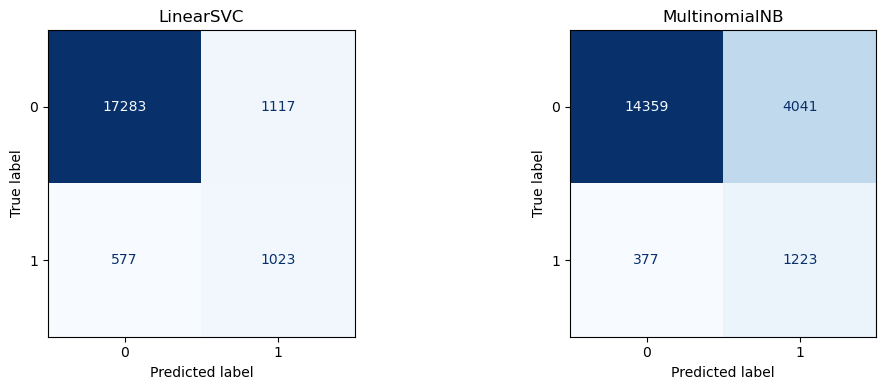

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, (model_name, predictions) in zip(axes, test_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        test["label"], predictions,
        labels=[0, 1], display_labels=[0, 1],
        cmap="Blues", colorbar=False, ax=ax,
    )
    ax.set_title(model_name)
    print(model_name)
    print(classification_report(
        test["label"], predictions, labels=[0, 1],
        digits=4, zero_division=0,
    ))

plt.tight_layout()
plt.show()

In [31]:
chosen_model = valid_metrics.iloc[0]["model"]

errors = test[["comment_text", "label"]].copy()
errors["prediction"] = test_predictions[chosen_model]
errors = errors.loc[errors["label"] != errors["prediction"]]

error_examples = pd.concat([
    errors.loc[errors["label"] == 0].head(3),
    errors.loc[errors["label"] == 1].head(2),
])
if len(error_examples) < 5:
    remaining = errors.loc[~errors.index.isin(error_examples.index)]
    error_examples = pd.concat([
        error_examples, remaining.head(5 - len(error_examples)),
    ])

print("Разбираем ошибки:", chosen_model)
with pd.option_context("display.max_colwidth", None):
    display(error_examples.rename_axis("document_id").reset_index())

Разбираем ошибки: LinearSVC


,document_id,comment_text,label,prediction
0,1112731,"I've often disagreed with Sarah but on this one I think she is right. Someone has to hold these yo yo's accountable. Of course they knew it was false but they print crap like this all the time and probably just thought they could get away with it again. I do like the fact that she pointed out that there was no similar coverage about pelosi, celebrities and the media being overtly hostile as well. And the fact that this was reported as a 'correction' and not a retraction and they couldn't even bring themselves to say her name. Really pathetic but par for the course for the new york times.",0,1
1,938119,"A post of pure insult, no content but contempt.\nWho pays these guys?",0,1
2,715237,"Emelin. A hypothetical -- he's sent down, grabbed off waivers and the other team sends a sack of ashes in return.",0,1
3,1055532,"Modern Toronto is garbage, a slave wage cesspool. It used to be a nice place where people lived balanced lives. Now it is a greedy slimy cesspool.",1,0
4,64420,"KK- If you had a shred of integrity, you would attempt to base your comments on fact. Few faculty at universities make six figure salaries. Many become administrators so that they can achieve that level of pay. Even George W. earns hundreds of thousands of dollars when he makes a speech, though God knows what kind of moron would pay him to speak. To call Norway a welfare state is accurate - they set their economy and government up to take care of the welfare of ALL of their citizens and not just the top tier. If its a welfare state to have free, high quality healthcare, education, and childcare for all, high-quality jobs that pay a livable wage - sign me up! How many people in the U.S. are stressing over the cost of medical care? Millions! Even university faculty stress over the possibility of the U taking away the healthcare benefit. In the U.S. we want CEOs to get richer and richer at the expense of middle class and poor Americans. It is our national religion and it is disgusting.",1,0


В Test 92% комментариев нетоксичные. Если всегда предсказывать этот класс, Accuracy составит 92%, а полнота токсичного класса будет нулевой. Макрометрики дают обоим классам одинаковый вес.

На Test лучший результат показал LinearSVC с нашей очисткой: Macro Precision = **0,7229**, Macro Recall = **0,7893**, Macro F1 = **0,7502**. MultinomialNB с лемматизацией получил Macro F1 = **0,6115**. У NB выше полнота токсичного класса (0,7644 против 0,6394 у SVM), но существенно ниже точность этого класса (0,2323 против 0,4780): он обнаруживает больше токсичных комментариев ценой большего числа ложных срабатываний.

Анализ пяти ошибок показывает трудности с резкой критикой, упоминанием оскорблений, контекстными метафорами и оскорбительными фрагментами внутри длинных текстов.


1. 1112731 — ложное срабатывание: crap, pathetic, hostile, yo yo's — негативная и уничижительная лексика.
2. 938119 — ложное срабатывание: insult, contempt — слова об оскорблениях, хотя автор описывает чужой пост.
3. 715237 — ложное срабатывание: sack, ashes — возможные сигналы; здесь особенно трудно объяснить прогноз без просмотра вкладов признаков.
4. 1055532 — пропуск токсичности: garbage, cesspool, greedy, slimy должны были служить сигналами токсичности, но итоговый прогноз оказался 0.
5. 64420 — пропуск токсичности: moron, disgusting, фраза shred of integrity — возможные сигналы, которые могли потеряться на фоне остального текста.

## Этап 4. Построение инвертированного индекса

Для индекса берём всю подвыборку из 100 000 комментариев.

In [32]:
def search_tokens(text):
    return [
        token for token in clean_tokens(text)
        if any(char.isalnum() for char in token)
    ]

In [33]:
corpus = subset[["comment_text"]].copy()

In [34]:
inverted_index = defaultdict(list)
doc_counts = {}
doc_lengths = {}

for doc_id, text in corpus["comment_text"].items():
    counts = Counter(search_tokens(text))
    doc_counts[doc_id] = counts
    doc_lengths[doc_id] = sum(counts.values())
    for token in counts:
        inverted_index[token].append(doc_id)

N = len(corpus)
avgdl = sum(doc_lengths.values()) / N

In [35]:
print("Документов:", N)
print("Уникальных поисковых токенов:", len(inverted_index))
print("Средняя длина документа:", round(avgdl, 2))
print("Первые ID для healthcare:", inverted_index.get("healthcare", [])[:10])

Документов: 100000
Уникальных поисковых токенов: 78329
Средняя длина документа: 52.09
Первые ID для healthcare: [710041, 1268292, 979208, 1110664, 1256009, 985981, 1092016, 1170204, 1613548, 410635]


## Этап 5. Полнотекстовый поиск BM25

Для каждого уникального токена запроса суммируем вклад:

$$
\mathrm{score}(d,q)=\sum_{t\in\mathrm{unique}(q)}
\ln\left(1+\frac{N-df_t+0.5}{df_t+0.5}\right)
\frac{f_{t,d}(k_1+1)}{f_{t,d}+k_1(1-b+b|d|/\mathrm{avgdl})}.
$$

* `df` — число документов со словом
* `f` — число вхождений слова в конкретном документе
* фиксированные параметры: `k1=1.5`, `b=0.75`.

In [36]:
def search_bm25(query, top_k=5, k1=1.5, b=0.75):
    if top_k < 1 or k1 <= 0 or not 0 <= b <= 1:
        raise ValueError("Нужны top_k >= 1, k1 > 0 и 0 <= b <= 1")

    scores = defaultdict(float)
    for token in dict.fromkeys(search_tokens(query)):
        postings = inverted_index.get(token, [])
        if not postings:
            continue

        df = len(postings)
        idf = math.log(1 + (N - df + 0.5) / (df + 0.5))
        for doc_id in postings:
            frequency = doc_counts[doc_id][token]
            length_norm = 1 - b + b * doc_lengths[doc_id] / avgdl
            scores[doc_id] += (
                idf * frequency * (k1 + 1)
                / (frequency + k1 * length_norm)
            )

    ranked = sorted(scores.items(), key=lambda item: (-item[1], item[0]))[:top_k]
    return pd.DataFrame([
        {
            "document_id": doc_id,
            "score": score,
            "comment_text": corpus.at[doc_id, "comment_text"],
        }
        for doc_id, score in ranked
    ], columns=["document_id", "score", "comment_text"])

In [37]:
queries = [
    "healthcare insurance",
    "hockey player team",
    "government taxes economy",
]

search_results = {}
for query in queries:
    results = search_bm25(query)
    search_results[query] = results
    print("Запрос:", query)
    with pd.option_context("display.max_colwidth", None):
        display(results)

Запрос: healthcare insurance


,document_id,score,comment_text
0,1255428,16.088431,With nationalized healthcare do all doctors participate equally? Do any citizens in countries with nationalized healthcare ever purchase private insurance?
1,1204675,15.863754,Healthcare which was covered by the senator's employer-provided insurance.
2,1293696,15.702312,The people who helped elect him. Point being you can't fix Obamacare without leaving the central government in control of our nation's healthcare and health insurance. The people who helped elected him wants the central government out of the people's healthcare and health insurance. They have control Medicaid and Medicare there is no reason for them to be in control of everyone else's healthcare and health insurance.
3,1190217,15.279266,"The banks have paid it back plus interest, so there was no lost money. Actually the cost in secondary to my objection to government run healthcare/insurance. Control the nation's healthcare and you control the people. That would never happen with private insurance."
4,425856,14.911585,"America:\nWhy give the money to the insurance industrial complex?\njust pay for healthcare, keep the money that insurance needs to run its money generating entity.\nno insurance = low cost healthcare.\nwe are like sheep being led to slaughter by an industry that really does not care about your health,\nthey care about Premiums you can pay for there CEO."


Запрос: hockey player team


,document_id,score,comment_text
0,422876,18.255651,Canada's favorite NHL hockey team - by far.
1,1612373,17.277682,Pretty much the whitest hockey team that I've ever seen.\nCoincidence?
2,769794,17.045648,Bettman is so hated. He really does so many annoying things. Why couldn't he have brought a more famous hockey player instead?
3,353984,16.826965,I find they look and sound more like an NBA team than Hockey.
4,595782,16.193321,It's a good thing they didn't also mention Flin Flon's hockey team in the PayPal transaction!


Запрос: government taxes economy


,document_id,score,comment_text
0,818517,13.915249,"It's arguable, if it's the 6th largest economy in the world or not. It is a diverse economy with high taxes. Business that could leave, left Califoria, I know many people that left California due to taxes and progressive agendas. California is the #1 state for wealth redistribution by the government, mecca for free stuff, capital of moral decay in the big cities and great weather. I guess the weather keeps residents for voting for more taxes😎"
1,1469705,13.023743,"The other 99% don't face 54% confiscation of their rightful earnings.\nBut the real issue is that taxes are too high at all levels. We do not need this much government. In fact, it holds our economy back."
2,188125,12.938448,"Says a guy who lives in the biggeest welfare state in the union, who pays not state taxes, who has the lowest tax burden in the nation who gets money from the state government, who lives in the state where we recieve $6 for every dollar we pay in taxes. The state where the biggest contributor to the economy is the government. Yeah you're a real Goldwater there buddy...."
3,720459,12.885364,"Meanwhile.......in Minnesota, which raised income taxes.......their economy is doing well: https://www.minnpost.com/community-voices/2017/03/staying-course-daytons-brand-budgeting-structural-balance-and-it-works"
4,1547756,12.612129,"Balt you are totally ignoring the growth in the economy and hence taxable revenue that these cuts will generate, not to mention the billions that are left offshore to avoid paying excessive taxes on cash that is not needed at home yet. Every penny increase in after tax income is a penny increase in the economy. It is not the nations wealth, only once taxes have been paid is it Government money, and that should only be used to enhance an environment in which the citizens of the country can be productive, and free of outside interference, which includes government."


Для `healthcare insurance` выдача содержит обсуждения медицинского страхования и организации здравоохранения; первый результат (ID 1255428) напрямую связывает государственное здравоохранение с частным страхованием. Для `hockey player team` найдены комментарии о хоккейных командах и игроках. Для `government taxes economy` результаты касаются налогов, роли государства и экономики

Выдача иллюстрирует поиск по совпадению части слов: например, первый результат хоккейного запроса (ID 422876) содержит `hockey` и `team`, но не `player`. Аналогично результат ID 720459 экономического запроса содержит `taxes` и `economy`, но не `government`

## Этап 6. Тематическое моделирование (LDA)

Для LDA используем нашу очистку с лемматизацией WordNet в режиме существительных. Убираем английские стоп-слова, числа, пунктуацию, слова короче трёх букв и нелатинские слова.

In [38]:
lda_texts = [
    [
        token for token in lemma_tokens(text)
        if re.fullmatch(r"[a-z]{3,}", token)
        and token not in ENGLISH_STOP_WORDS
    ]
    for text in subset["comment_text"]
]

lda_dictionary = Dictionary(lda_texts)
lda_dictionary.filter_extremes(
    no_below=20,
    no_above=0.5,
    keep_n=20_000,
)

lda_texts = [
    [token for token in tokens if token in lda_dictionary.token2id]
    for tokens in lda_texts
]
lda_texts = [tokens for tokens in lda_texts if tokens]
lda_corpus = [lda_dictionary.doc2bow(tokens) for tokens in lda_texts]

print("Непустых документов:", len(lda_corpus))
print("Размер словаря:", len(lda_dictionary))
assert len(lda_dictionary) >= 10 and len(lda_corpus) > 0

Непустых документов: 99294
Размер словаря: 9702


In [39]:
k_values = [5, 10, 15, 20]
lda_models = {}
coherence_rows = []

for k in k_values:
    model = LdaModel(
        corpus=lda_corpus,
        id2word=lda_dictionary,
        num_topics=k,
        random_state=SEED,
        passes=5,
        iterations=50,
        chunksize=2000,
        eval_every=None,
    )

    coherence = CoherenceModel(
        model=model,
        texts=lda_texts,
        dictionary=lda_dictionary,
        coherence="c_v",
        topn=10,
        processes=1,
    ).get_coherence()

    lda_models[k] = model
    coherence_rows.append({"K": k, "c_v": coherence})
    print(f"K={k}: C_V={coherence:.4f}")

K=5: C_V=0.6097
K=10: C_V=0.6463
K=15: C_V=0.6274
K=20: C_V=0.6487


,K,c_v
0,5,0.609735
1,10,0.646257
2,15,0.627391
3,20,0.648694


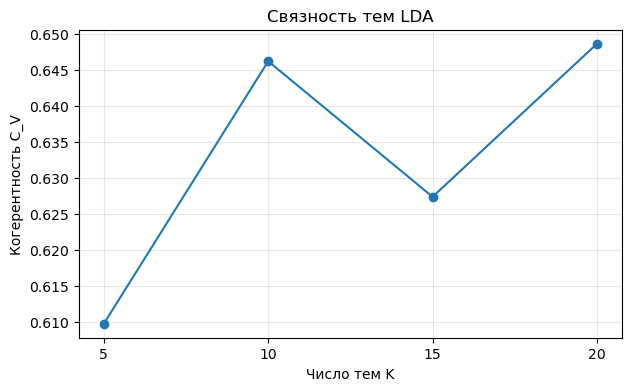

In [40]:
coherence_results = pd.DataFrame(coherence_rows)
display(coherence_results)

plt.figure(figsize=(7, 4))
plt.plot(coherence_results["K"], coherence_results["c_v"], marker="o")
plt.xticks(k_values)
plt.xlabel("Число тем K")
plt.ylabel("Когерентность C_V")
plt.title("Связность тем LDA")
plt.grid(alpha=0.3)
plt.show()

In [41]:
best_k = int(coherence_results.loc[coherence_results["c_v"].idxmax(), "K"])
best_lda = lda_models[best_k]
print("Лучшее K по C_V среди проверенных:", best_k)

Лучшее K по C_V среди проверенных: 20


## Этап 7. Интерпретация тем

При K = 20 когерентность выше, чем при других проверенных K. Ближайший результат даёт K = 10 (0,6463 против 0,6487), поэтому преимущество 20 тем по этой метрике невелико.

In [42]:
topic_rows = []
for topic_id in range(best_k):
    top_words = best_lda.show_topic(topic_id, topn=10)
    topic_rows.append({
        "topic_id": topic_id,
        "top_10_words": ", ".join(word for word, weight in top_words),
        "weights": [round(float(weight), 4) for word, weight in top_words],
    })

topics_table = pd.DataFrame(topic_rows)
with pd.option_context("display.max_colwidth", None):
    display(topics_table)

,topic_id,top_10_words,weights
0,0,"tax, money, pay, government, cost, business, job, year, million, income","[0.0377, 0.0271, 0.024, 0.0192, 0.0168, 0.0135, 0.0107, 0.0106, 0.0101, 0.0099]"
1,1,"time, game, good, guy, year, great, team, play, best, better","[0.0158, 0.0153, 0.0144, 0.0143, 0.0142, 0.0134, 0.0118, 0.011, 0.01, 0.0096]"
2,2,"year, ago, long, hawaii, native, time, term, old, past, ndp","[0.0582, 0.0194, 0.0148, 0.0134, 0.0128, 0.0114, 0.0105, 0.0098, 0.0088, 0.0083]"
3,3,"canada, canadian, country, trudeau, china, american, world, government, immigrant, usa","[0.0609, 0.0503, 0.0477, 0.0243, 0.0192, 0.019, 0.0185, 0.017, 0.0146, 0.0139]"
4,4,"woman, life, child, family, people, kid, year, men, man, parent","[0.0248, 0.0233, 0.0191, 0.0176, 0.0171, 0.0141, 0.0108, 0.0104, 0.0095, 0.0093]"
5,5,"white, news, right, war, gun, black, people, medium, crime, racist","[0.0274, 0.0228, 0.0191, 0.0187, 0.0187, 0.0162, 0.0159, 0.014, 0.0134, 0.0129]"
6,6,"comment, article, post, read, thanks, point, reading, civil, globe, nice","[0.0614, 0.0406, 0.0344, 0.034, 0.0213, 0.0159, 0.0138, 0.0117, 0.0107, 0.01]"
7,7,"trump, vote, party, president, republican, election, obama, democrat, voter, hillary","[0.1002, 0.0339, 0.0318, 0.0301, 0.0266, 0.0226, 0.0204, 0.0184, 0.0137, 0.0118]"
8,8,"like, just, people, know, think, thing, say, make, good, want","[0.0427, 0.0355, 0.0329, 0.0289, 0.0254, 0.0217, 0.0209, 0.0185, 0.0185, 0.0161]"
9,9,"clinton, free, speech, democratic, bush, supporter, yeah, north, pro, korea","[0.0399, 0.0236, 0.0202, 0.0168, 0.0135, 0.0133, 0.0129, 0.0127, 0.0127, 0.0115]"


| ID | Условное название | Основание и описание |
|---|---|---|
| 0 | Налоги, доходы и бизнес | `tax, money, pay, cost, business, income`: налоги, заработок и экономические расходы. |
| 1 | Спорт и оценка игры | `game, team, play, best`: обсуждение команд и игры с общей оценочной лексикой. |
| 2 | Временные и региональные отсылки — смешанная | `year, ago, past, hawaii, native, ndp`: временные указания и региональные упоминания; единая предметная тема выражена слабо. |
| 3 | Канада и международная политика | `canada, canadian, trudeau, china, immigrant`: Канада, отношения между странами и миграция. |
| 4 | Семья, дети и гендер | `woman, child, family, kid, men, parent`: семейные отношения и обсуждение мужчин и женщин. |
| 5 | Расовые вопросы и общественные конфликты — смешанная | `white, black, racist, gun, crime, war`: расовые вопросы, преступность и насилие; также присутствует лексика СМИ. |
| 6 | Обсуждение публикаций и комментариев | `comment, article, post, read, thanks`: реакции читателей на статьи и общение в комментариях. |
| 7 | Выборы и партийная политика США | `trump, vote, republican, election, obama, democrat`: выборы, партии и политические лидеры США. |
| 8 | Общая разговорная лексика | `like, just, know, think, thing, want`: частые слова рассуждений без чёткой предметной темы. |
| 9 | Политические фигуры и свобода слова — смешанная | `clinton, speech, democratic, bush, north, korea`: политические упоминания, слабо объединённые в одну тему. |
| 10 | Религия | `church, god, catholic, christian, muslim, belief`: религиозные институты, верования и конфессии. |
| 11 | Политические расследования и коррупция | `liberal, conservative, investigation, campaign, fraud, corruption`: партии, кампании и обвинения в нарушениях. |
| 12 | Город и жильё | `city, home, house, property, housing`: городская жизнь, недвижимость и жилищные вопросы. |
| 13 | Здравоохранение и страхование | `care, health, insurance, medical, mental`: медицинская помощь, страхование и проблемы здоровья. |
| 14 | Государственные проекты и военная политика — смешанная | `wall, military, mexico, build, nuclear, water`: разнородные политические и инфраструктурные сюжеты, единство темы неочевидно. |
| 15 | Транспорт и дорожное движение | `car, road, rail, vehicle, driving, traffic`: автомобили, железные дороги и движение. |
| 16 | Аляска и энергетические ресурсы | `oil, alaska, gas, alaskan, industry, energy`: нефтегазовая отрасль и региональная политика Аляски. |
| 17 | Происшествия и бытовые истории — смешанная | `story, police, dog, hit, night`: повествовательная лексика и упоминания происшествий; требуется просмотр документов для уточнения. |
| 18 | Право и государственное образование | `law, public, school, court, case, student`: правовые и общественные вопросы, включая школы. |
| 19 | Аргументация и обсуждение доказательств | `fact, evidence, study, science, argument, opinion`: ссылки на факты, исследования и обоснование мнений. |